<a href="https://colab.research.google.com/github/saraeudora/Pytorch-Tutorial/blob/main/ROV_Video_Frame_Extraction_and_CLIP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Install the required libraries

In [1]:
!pip install -q opencv-python-headless transformers torch torchvision pillow matplotlib pandas

Import the libraries

In [2]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image
from google.colab import files

print("OpenCV version:", cv2.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


OpenCV version: 4.14.0
PyTorch version: 2.14.1+cu130
GPU available: True


Upload your ROV maintenance video

In [5]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [6]:
import os

video_path = "/content/drive/MyDrive/ROV_FYP/videos/converted-IMG_9770.mp4"

if os.path.exists(video_path):
    print("Video found!")
    print("File:", video_path)
    print("Size:", round(os.path.getsize(video_path) / (1024 * 1024), 2), "MB")
else:
    print("Video not found. Please check the folder and filename.")


Video found!
File: /content/drive/MyDrive/ROV_FYP/videos/converted-IMG_9770.mp4
Size: 26.36 MB


Check whether OpenCV can read your video

In [7]:
import cv2

cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError("OpenCV cannot open the video!")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = total_frames / fps if fps > 0 else 0

print("Video successfully loaded!")
print("FPS:", fps)
print("Total frames:", total_frames)
print("Resolution:", width, "x", height)
print("Duration:", round(duration, 2), "seconds")

cap.release()


Video successfully loaded!
FPS: 30.0
Total frames: 778
Resolution: 1920 x 1080
Duration: 25.93 seconds


Extract your ROV video frames using openCV

In [8]:

import os
import cv2
from PIL import Image

output_folder = "/content/rov_frames"
os.makedirs(output_folder, exist_ok=True)

cap = cv2.VideoCapture(video_path)

interval_seconds = 1
frame_interval = max(1, round(fps * interval_seconds))

frame_count = 0
saved_count = 0

extracted_frames = []
frame_paths = []

while True:

    ret, frame = cap.read()

    if not ret:
        break

    if frame_count % frame_interval == 0:

        frame_rgb = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        pil_image = Image.fromarray(frame_rgb)

        frame_name = f"frame_{saved_count:03d}.jpg"
        frame_path = os.path.join(
            output_folder,
            frame_name
        )

        pil_image.save(frame_path)

        extracted_frames.append(pil_image)
        frame_paths.append(frame_path)

        saved_count += 1

    frame_count += 1

cap.release()

print("Total frames extracted:", saved_count)


Total frames extracted: 26


Load the CLIP Model

In [9]:
!pip install -q transformers torch torchvision pillow

In [10]:
import torch
import matplotlib.pyplot as plt
from transformers import CLIPProcessor, CLIPModel

# Load the pretrained CLIP model
model_name = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(model_name)
processor = CLIPProcessor.from_pretrained(model_name)

# Select GPU if available, otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"

model = model.to(device)
model.eval()

print("CLIP model loaded successfully!")
print("Device:", device)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP model loaded successfully!
Device: cuda


Define ROV maintenance activity descriptions

In [11]:
activities = [
    "A worker is inspecting an ROV component.",
    "A worker is removing a component from an ROV.",
    "A worker is installing or replacing an ROV component.",
    "A worker is preparing maintenance tools.",
    "A worker is cleaning an ROV component.",
    "A worker is visually observing an ROV.",
    "A worker is checking the condition of a component.",
    "A worker is working on an ROV without using any tools."
]

Display all frames in a grid

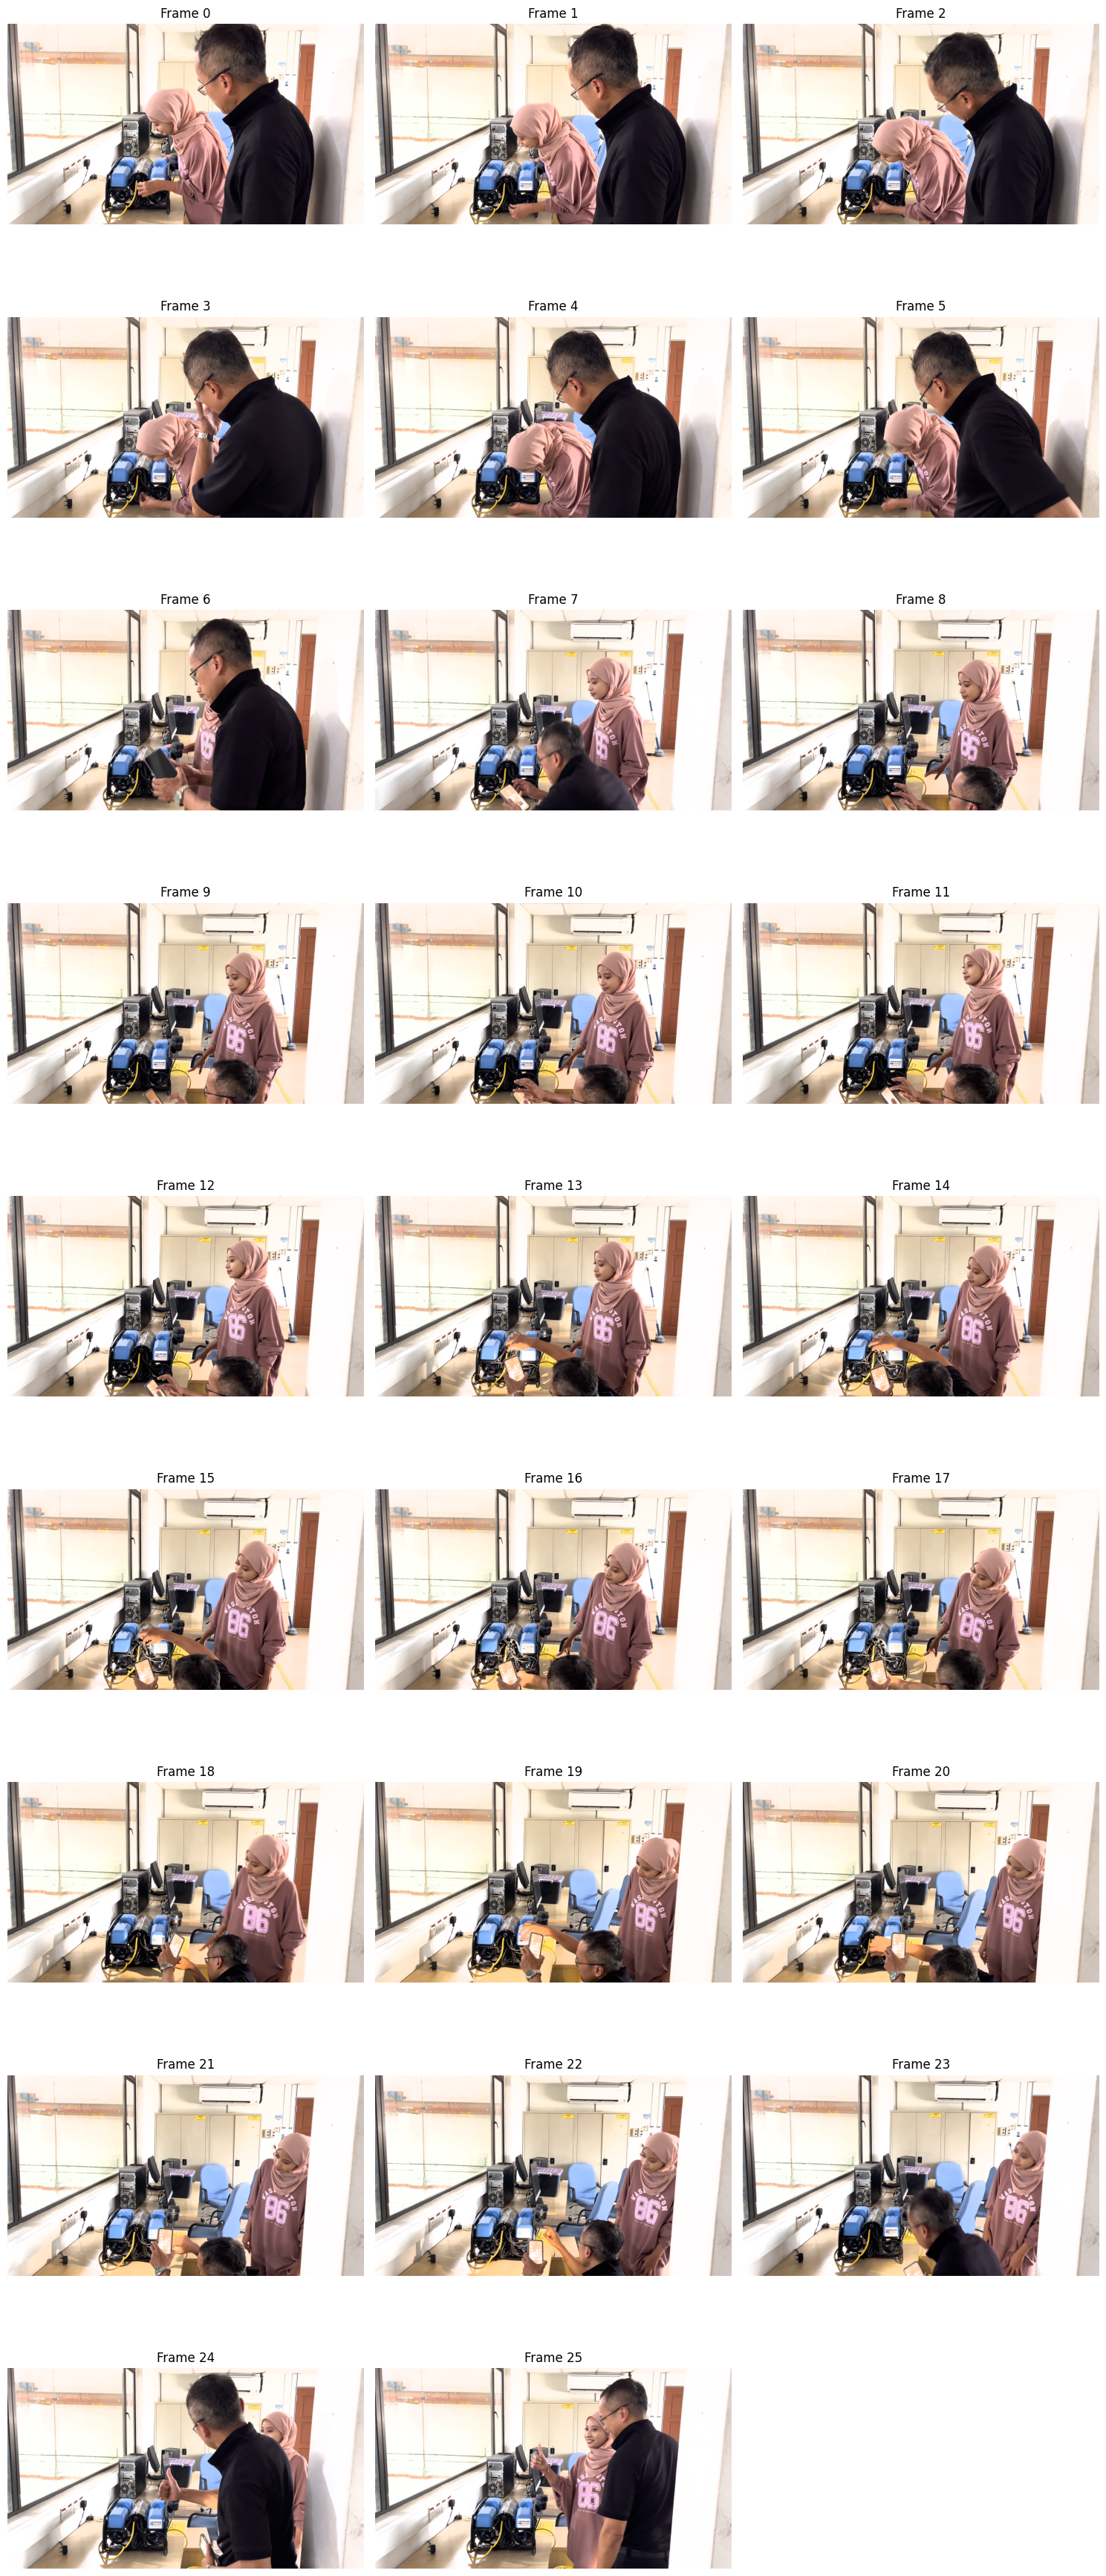

In [12]:
import matplotlib.pyplot as plt
import math

num_frames = len(extracted_frames)

cols = 3
rows = math.ceil(num_frames / cols)

plt.figure(figsize=(15, rows * 4))

for i, image in enumerate(extracted_frames):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)
    plt.title(f"Frame {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Test CLIP on one extracted frame

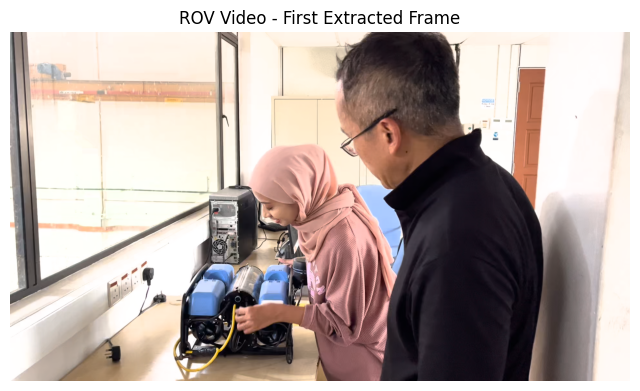

In [13]:
# Select the first extracted frame
image = extracted_frames[0]

# Display the image
plt.figure(figsize=(8, 5))
plt.imshow(image)
plt.axis("off")
plt.title("ROV Video - First Extracted Frame")
plt.show()

compare it with the activity descriptions

In [14]:
# Prepare the image and text descriptions
inputs = processor(
    text=activities,
    images=image,
    return_tensors="pt",
    padding=True
)

# Move inputs to the selected device
inputs = {key: value.to(device) for key, value in inputs.items()}

# Run CLIP inference
with torch.no_grad():
    outputs = model(**inputs)

# Calculate similarity scores
similarity = outputs.logits_per_image.softmax(dim=1)

# Display results
scores = similarity[0].cpu().numpy()

for activity, score in zip(activities, scores):
    print(f"{activity}: {score:.4f}")

A worker is inspecting an ROV component.: 0.2056
A worker is removing a component from an ROV.: 0.0262
A worker is installing or replacing an ROV component.: 0.0504
A worker is preparing maintenance tools.: 0.0147
A worker is cleaning an ROV component.: 0.0146
A worker is visually observing an ROV.: 0.2537
A worker is checking the condition of a component.: 0.0423
A worker is working on an ROV without using any tools.: 0.3926


The highest similarity score (0.2537) was obtained for "A worker is visually observing an ROV." However, this result comes from OpenAI's pretrained CLIP model, not a model trained or fine-tuned on my own ROV maintenance dataset